# 03 · Preserve positional correlations

Two ordered sequences contain the same multiset of directions. Their global moments agree at every order. Their lag-dependent correlations differ. This experiment uses an ordered vector sequence without assigning language meaning.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

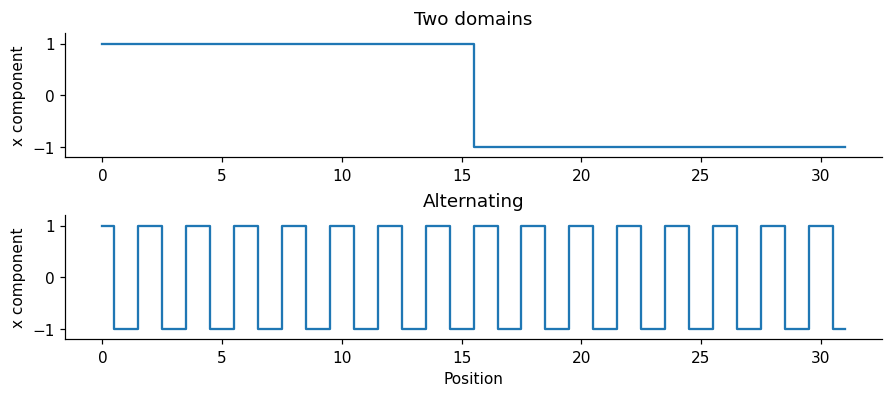

,lag,blocks,alternating
0,0,1.000,1.0
1,1,0.875,-1.0
2,2,0.750,1.0
3,3,0.625,-1.0
4,4,0.500,1.0


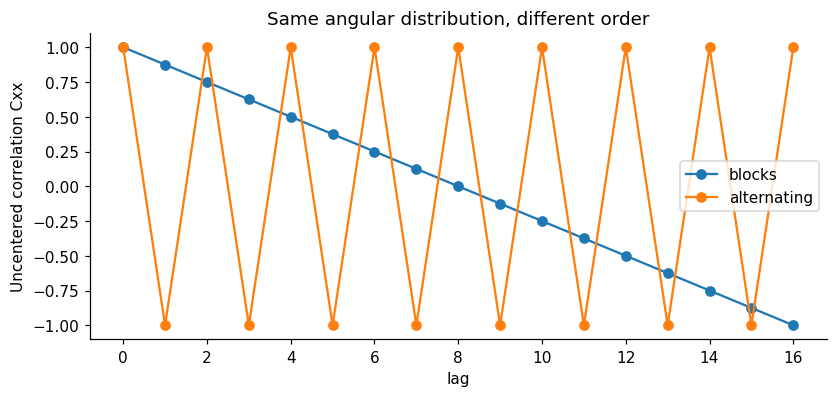

In [5]:
a,b=symbolic_sequence('blocks'),symbolic_sequence('alternating')
fig,axes=plt.subplots(2,1,figsize=(8,3.5))
for ax,x,title in zip(axes,[a,b],['Two domains','Alternating']):
    ax.step(range(len(x)),x[:,0],where='mid');ax.set(ylim=(-1.2,1.2),ylabel='x component',title=title)
axes[-1].set_xlabel('Position');show('03_sequences')
assert np.allclose(np.sort(a,axis=0),np.sort(b,axis=0))
for k in (1,2,3,4):
    assert np.allclose(tensor_moment(a,k),tensor_moment(b,k))
rows=[]
for lag in range(17):
    rows.append((lag,periodic_correlation(a,lag)[0,0],periodic_correlation(b,lag)[0,0]))
corr=pd.DataFrame(rows,columns=['lag','blocks','alternating'])
display(corr.head().round(3))
corr.plot(x='lag',marker='o');plt.ylabel('Uncentered correlation Cxx');plt.title('Same angular distribution, different order')
show('03_lag_correlation')

## Matrix spectra retain more than the trace
For a real vector field $h_i$ on a periodic sequence, $F(k)=\sum_i h_i e^{-2\pi iki/N}$ and $\mathcal S(k)=F(k)F(k)^\dagger/N$. The trace is the scalar power summed over feature channels. Taking a trace removes cross-channel information. Centering removes the DC component. The notebooks specify when centering is applied.

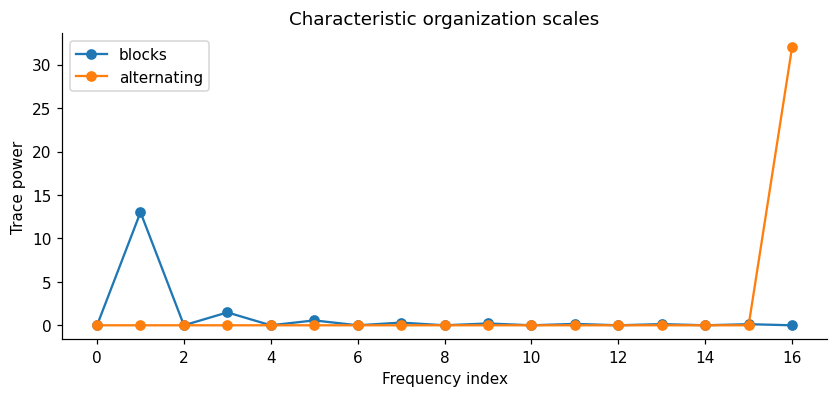

In [7]:
for x,label in [(a,'blocks'),(b,'alternating')]:
    f=np.fft.fft(x,axis=0)
    trace=(np.abs(f)**2).sum(1)/len(x)
    plt.plot(np.arange(17),trace[:17],marker='o',label=label)
plt.xlabel('Frequency index');plt.ylabel('Trace power');plt.title('Characteristic organization scales')
plt.legend();show('03_sequence_spectra')

## Interpretation
A permutation-invariant observable cannot distinguish two permutations of the same feature multiset. Correlations restore a selected notion of relative position. Periodicity introduces a link between the end and start; finite documents normally need explicit open boundaries and lag-dependent overlap counts. A field of local Q-tensors can similarly retain spatial variation in axial order.